# 2. Policy Comparison

How much does the bandwidth-allocation policy actually matter? We compare
four reference policies (`max_bandwidth`, `min_bandwidth`,
`queue_proportional`, `random`) from `examples/random_agent_test.py` on
both synthetic Poisson traffic and a real packet-capture trace, and plot
the gap between them.

This is the evidence that there's something worth training an RL agent
on in the first place.

In [1]:
import sys, os
REPO_ROOT = os.path.abspath("..")
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)
os.chdir(REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from carla_gym.env import CarlaGymEnv
from carla_gym.core.trace_traffic import TraceTrafficGenerator
from examples.random_agent_test import (
    policy_random, policy_max, policy_min, policy_queue_proportional,
)

plt.rcParams["figure.dpi"] = 100

POLICIES = {
    "max_bandwidth": policy_max,
    "queue_proportional": policy_queue_proportional,
    "random": policy_random,
    "min_bandwidth": policy_min,
}

In [2]:
def run_policy(make_env, fn, episodes=3, steps=150, warmup=20, seed=42):
    rows = []
    for ep in range(episodes):
        env = make_env(seed + ep)
        obs, _ = env.reset(seed=seed + ep)
        rng = np.random.default_rng(seed + ep)
        for t in range(steps):
            action = fn(env, obs, rng)
            obs, reward, terminated, truncated, info = env.step(action)
            if t >= warmup:
                rows.append({
                    "episode": ep, "step": t, "reward": reward,
                    "throughput": info["reward_throughput"],
                    "loss": info["reward_loss"],
                    "latency": info["mean_latency_steps"],
                })
            if terminated or truncated:
                break
    return pd.DataFrame(rows)

## Synthetic Poisson traffic, bandwidth_budget=0.8

In [3]:
def make_synthetic_env(seed):
    return CarlaGymEnv(topology="grid", num_nodes=9, link_capacity=30, node_buffer=120,
                       bandwidth_budget=0.8, max_steps=150, seed=seed)

synthetic_results = {name: run_policy(make_synthetic_env, fn) for name, fn in POLICIES.items()}
synthetic_summary = pd.DataFrame({
    name: df[["reward", "throughput", "loss", "latency"]].mean()
    for name, df in synthetic_results.items()
}).T.sort_values("reward", ascending=False)
synthetic_summary

,reward,throughput,loss,latency
queue_proportional,0.151619,0.793628,0.165848,5.189947
max_bandwidth,-0.027213,0.748825,0.237104,6.178813
min_bandwidth,-0.999834,0.000000,0.999834,0.000000
random,-1.189734,0.358018,0.673348,20.877714


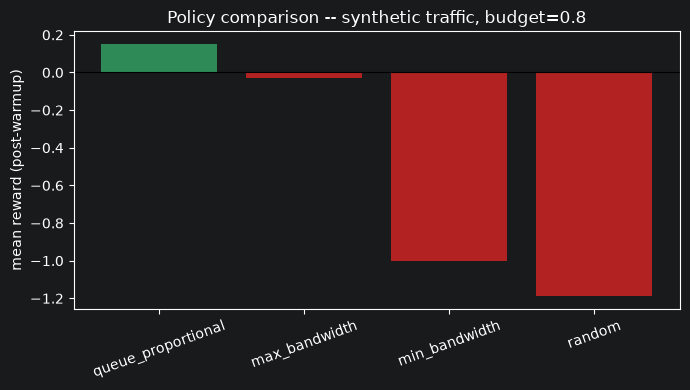

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
colors = ["seagreen" if v > 0 else "firebrick" for v in synthetic_summary["reward"]]
ax.bar(synthetic_summary.index, synthetic_summary["reward"], color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("mean reward (post-warmup)")
ax.set_title("Policy comparison -- synthetic traffic, budget=0.8")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Reward over time, all four policies

Same episode, four different allocation strategies -- this is the
clearest way to see that the policy genuinely changes the trajectory,
not just the final average.

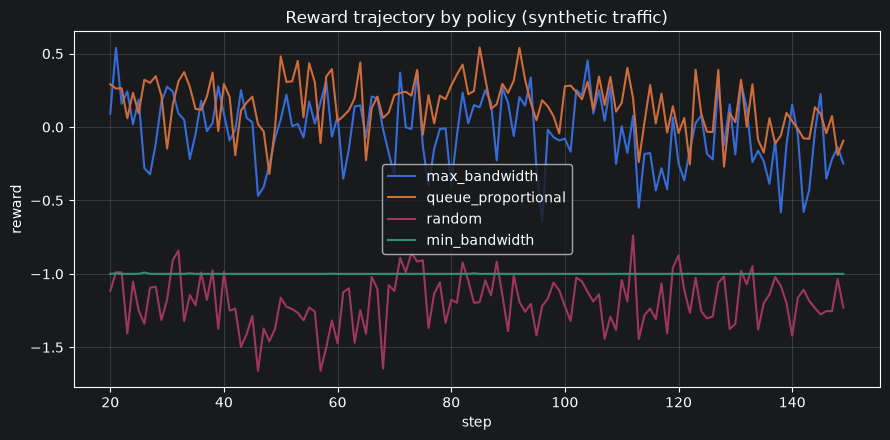

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, df in synthetic_results.items():
    series = df.groupby("step")["reward"].mean()
    ax.plot(series.index, series.values, label=name)
ax.set_xlabel("step")
ax.set_ylabel("reward")
ax.set_title("Reward trajectory by policy (synthetic traffic)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Throughput vs. loss trade-off

Each point is one policy's mean operating point. Good policies sit in
the top-left: high throughput, low loss.

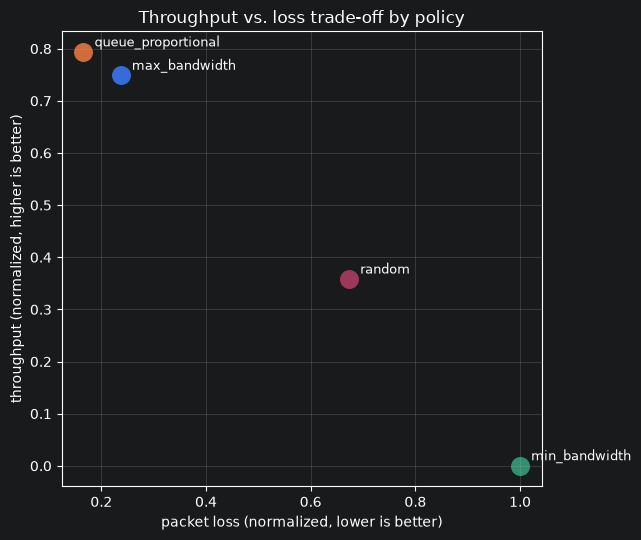

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name in POLICIES:
    row = synthetic_summary.loc[name]
    ax.scatter(row["loss"], row["throughput"], s=160, label=name)
    ax.annotate(name, (row["loss"], row["throughput"]),
               textcoords="offset points", xytext=(8, 4), fontsize=9)
ax.set_xlabel("packet loss (normalized, lower is better)")
ax.set_ylabel("throughput (normalized, higher is better)")
ax.set_title("Throughput vs. loss trade-off by policy")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Real packet-capture trace, bandwidth_budget=0.5

Real traffic concentrates on fewer src/dst pairs than the synthetic
generator spreads across the whole grid, so the budget that makes
allocation strategy matter is tighter here (0.5, not 0.8 -- see
README.md's "Calibration differs from synthetic traffic" section).

In [7]:
TRACE_PATH = "data/pcap_trace.csv"
assert os.path.exists(TRACE_PATH), (
    "Run `python scripts/prepare_trace.py --in data/output1.csv --out data/pcap_trace.csv` first."
)

def make_trace_env(seed):
    traffic = TraceTrafficGenerator(nodes=list(range(16)), csv_path=TRACE_PATH,
                                    target_load=110.0, seed=seed)
    return CarlaGymEnv(topology="grid", num_nodes=16, link_capacity=30, node_buffer=120,
                       bandwidth_budget=0.5, max_steps=150, traffic=traffic, seed=seed)

trace_results = {name: run_policy(make_trace_env, fn) for name, fn in POLICIES.items()}
trace_summary = pd.DataFrame({
    name: df[["reward", "throughput", "loss", "latency"]].mean()
    for name, df in trace_results.items()
}).T.sort_values("reward", ascending=False)
trace_summary

,reward,throughput,loss,latency
queue_proportional,-0.211801,0.340920,0.236871,4.297529
min_bandwidth,-0.456521,0.002608,0.457975,0.010256
max_bandwidth,-0.489667,0.152850,0.402266,3.991361
random,-0.563311,0.254831,0.333072,9.160922


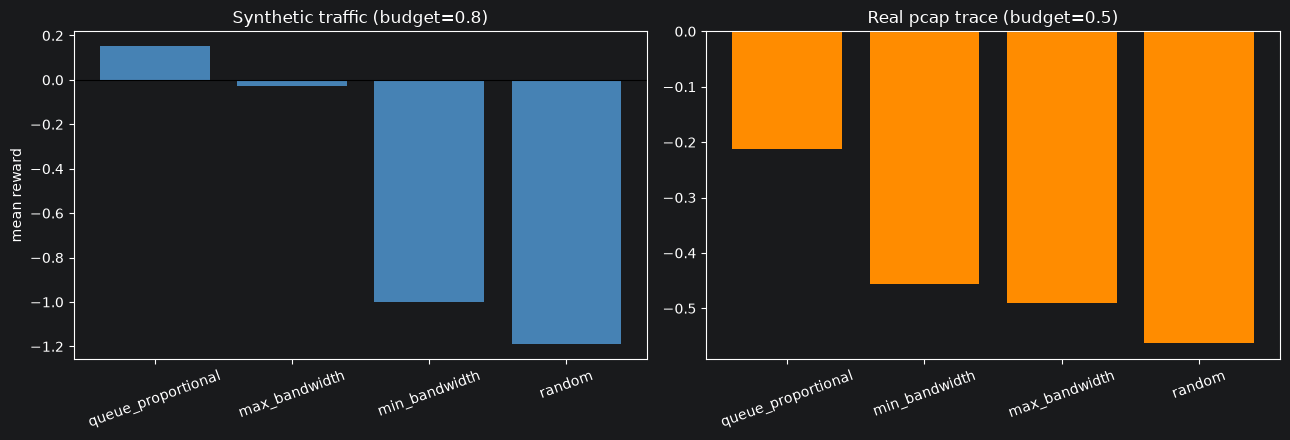

Note: queue_proportional beats max_bandwidth on the real trace at this
budget; at budget=0.8 (the synthetic-traffic setting) it does not, because
real traffic is concentrated enough that uniform allocation is still
fine until the budget is tighter.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

colors = ["seagreen" if v > synthetic_summary["reward"].min() else "firebrick"
         for v in synthetic_summary["reward"]]
axes[0].bar(synthetic_summary.index, synthetic_summary["reward"], color="steelblue")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Synthetic traffic (budget=0.8)")
axes[0].set_ylabel("mean reward")
axes[0].tick_params(axis="x", rotation=20)

axes[1].bar(trace_summary.index, trace_summary["reward"], color="darkorange")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Real pcap trace (budget=0.5)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

print("Note: queue_proportional beats max_bandwidth on the real trace at this")
print("budget; at budget=0.8 (the synthetic-traffic setting) it does not, because")
print("real traffic is concentrated enough that uniform allocation is still")
print("fine until the budget is tighter.")